In [6]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
import os
import cv2
from PIL import Image
import warnings
warnings.filterwarnings('ignore')

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


### DATA EXPLORATION

In [7]:
# Define paths (update these to your Kaggle dataset path)
train_dir =  r'chest_xray/train'
val_dir =  r'chest_xray/val'
test_dir =  r'chest_xray/test'

# Check class distribution
def count_images(directory):
    classes = os.listdir(directory)
    counts = {}
    for cls in classes:
        cls_path = os.path.join(directory, cls)
        if os.path.isdir(cls_path):
            counts[cls] = len(os.listdir(cls_path))
    return counts

print("Training set distribution:", count_images(train_dir))
print("Validation set distribution:", count_images(val_dir))
print("Test set distribution:", count_images(test_dir))

Training set distribution: {'NORMAL': 1341, 'PNEUMONIA': 3875}
Validation set distribution: {'NORMAL': 8, 'PNEUMONIA': 8}
Test set distribution: {'NORMAL': 234, 'PNEUMONIA': 390}


### DATA VISUALIZATION

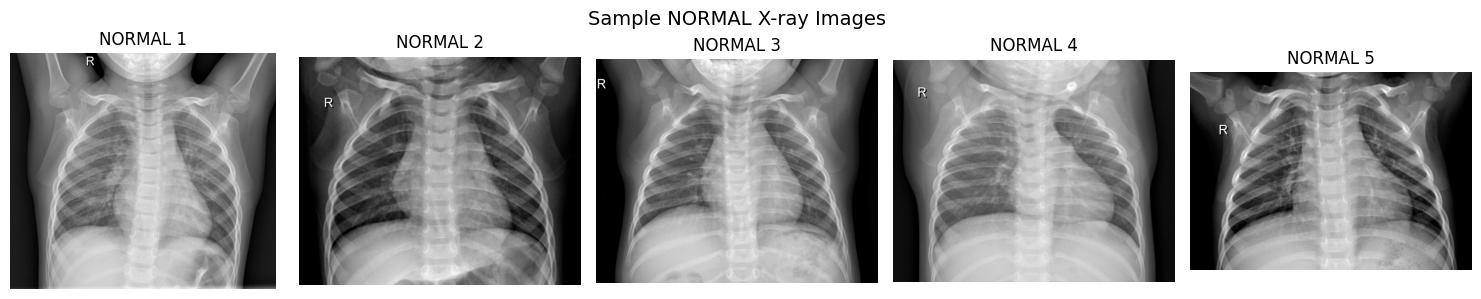

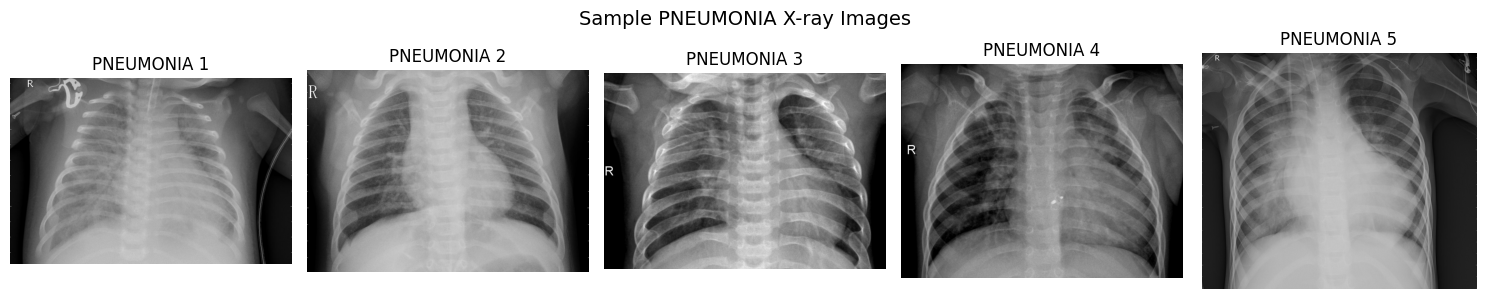

In [8]:
# Display sample images from each class
def plot_sample_images(directory, class_name, num_samples=5):
    class_path = os.path.join(directory, class_name)
    images = os.listdir(class_path)[:num_samples]
    
    fig, axes = plt.subplots(1, num_samples, figsize=(15, 3))
    fig.suptitle(f'Sample {class_name} X-ray Images', fontsize=14)
    
    for i, img_name in enumerate(images):
        img_path = os.path.join(class_path, img_name)
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        axes[i].imshow(img, cmap='gray')
        axes[i].axis('off')
        axes[i].set_title(f'{class_name} {i+1}')
    
    plt.tight_layout()
    plt.show()

# Plot samples from both classes
plot_sample_images(train_dir, 'NORMAL')
plot_sample_images(train_dir, 'PNEUMONIA')

### DATA PREPROCESSING AND AUGMENTATION

In [4]:
# 1. Define paths (Using your local directory paths)
train_dir = r'chest_xray/train'
test_dir =  r'chest_xray/test'

# 2. Set Parameters (Using 224 for compatibility with DenseNet/ResNet later)
IMG_SIZE = 224  
BATCH_SIZE = 32

# 3. Defining the Data Generator with a 20% Validation Split to solve the 16 image problem in validation set
train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,  # Takes 20% of training data for validation
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Rescaling for Testing
test_datagen = ImageDataGenerator(rescale=1./255)

# 4. Create Training Generator (80% of train_dir)
print("--- Loading Training Data ---")
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='training' 
)

# 5. Create Validation Generator (20% of train_dir)
print("\n--- Loading Validation Data (20% Split) ---")
validation_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='validation'
)

# 6. Create Test Generator
print("\n--- Loading Test Data ---")
test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

print(f"\nFinal Training samples: {train_generator.samples}")
print(f"Final Validation samples: {validation_generator.samples}")

--- Loading Training Data ---
Found 4173 images belonging to 2 classes.

--- Loading Validation Data (20% Split) ---
Found 1043 images belonging to 2 classes.

--- Loading Test Data ---
Found 624 images belonging to 2 classes.

Final Training samples: 4173
Final Validation samples: 1043


### BUILDING THE MODEL

In [5]:
from tensorflow.keras import layers, models

custom_cnn = models.Sequential([
    # Input layer must match the IMG_SIZE (224, 224) from your data generator
    layers.Input(shape=(224, 224, 3)),
    
    # Block 1
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    # Block 2
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    # Block 3
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3), # Added dropout to prevent overfitting
    
    # Block 4
    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.4), # Added higher dropout
    
    # Fully Connected
    layers.Flatten(),
    layers.Dense(512, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5), # Final dropout before output
    layers.Dense(1, activation='sigmoid') # Binary classification
])

custom_cnn.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.Recall(), tf.keras.metrics.AUC()]
)

custom_cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    25,690,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,083,521 (99.50 MB)

 Trainable params: 26,081,537 (99.49 MB)

 Non-trainable params: 1,984 (7.75 KB)

### COMPILING THE MODEL


In [6]:
# Compiling with Adam optimizer
custom_cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall(), tf.keras.metrics.AUC()]
)

### SETTING UP CALL BACKS

In [7]:
# Callbacks for better training
callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        'best_custom_cnn.keras',
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=5,
        min_lr=1e-7,
        verbose=1
    )
]

### TRAINING THE MODEL


In [8]:
# 1. Calculate class weights (ensures we handle the imbalance)
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_generator.classes),
    y=train_generator.classes
)
class_weight_dict = dict(enumerate(class_weights))
print("Class weights:", class_weight_dict)

# 2. Define Callbacks with the new .keras extension (Fixes the Warning)
checkpoint = ModelCheckpoint(
    'best_custom_cnn.keras',  
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=1
)

early_stopping = EarlyStopping(
    monitor='val_loss', 
    patience=10, 
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss', 
    factor=0.2, 
    patience=5, 
    min_lr=0.00001,
    verbose=1
)

# 3. Train the model 
# Using validation_generator (the one with the 20% split)
history = custom_cnn.fit(
    train_generator,
    steps_per_epoch=train_generator.samples // BATCH_SIZE, 
    epochs=50,
    validation_data=validation_generator,  
    validation_steps=validation_generator.samples // BATCH_SIZE,
    callbacks=[checkpoint, early_stopping, reduce_lr], 
    class_weight=class_weight_dict, 
    verbose=1
)

# 4. Save final model
custom_cnn.save('final_custom_cnn.keras')

Class weights: {0: np.float64(1.9445479962721341), 1: np.float64(0.6730645161290323)}
Epoch 1/50
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7530 - auc_1: 0.8718 - loss: 0.5551 - precision: 0.9390 - recall_1: 0.7123
Epoch 1: val_accuracy improved from None to 0.74414, saving model to best_custom_cnn.keras
130/130 ━━━━━━━━━━━━━━━━━━━━ 308s 2s/step - accuracy: 0.8174 - auc_1: 0.9163 - loss: 0.4105 - precision: 0.9588 - recall_1: 0.7879 - val_accuracy: 0.7441 - val_auc_1: 0.4784 - val_loss: 2.5106 - val_precision: 0.7441 - val_recall_1: 1.0000 - learning_rate: 0.0010
Epoch 2/50
  1/130 ━━━━━━━━━━━━━━━━━━━━ 4:18 2s/step - accuracy: 0.8125 - auc_1: 0.9391 - loss: 0.3828 - precision: 1.0000 - recall_1: 0.7692
Epoch 2: val_accuracy did not improve from 0.74414
130/130 ━━━━━━━━━━━━━━━━━━━━ 27s 191ms/step - accuracy: 0.8125 - auc_1: 0.9391 - loss: 0.3828 - precision: 1.0000 - recall_1: 0.7692 - val_accuracy: 0.7393 - val_auc_1: 0.4785 - val_loss: 2.5491 - val_precision: 0.7393 - val_r

### PLOTTING TRAINING HISTORY

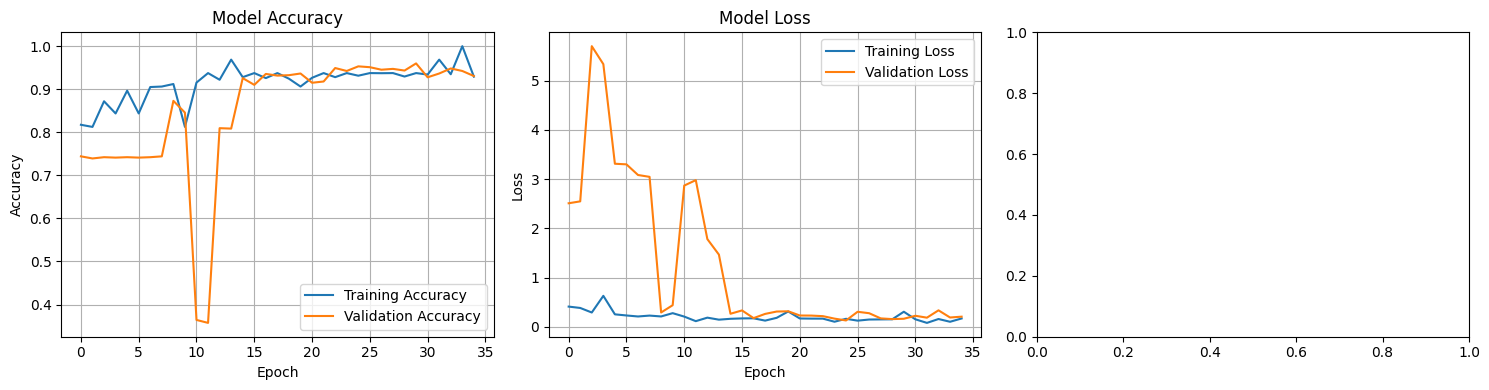

In [9]:
def plot_training_history(history):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    
    # Plot training & validation accuracy
    axes[0].plot(history.history['accuracy'], label='Training Accuracy')
    axes[0].plot(history.history['val_accuracy'], label='Validation Accuracy')
    axes[0].set_title('Model Accuracy')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[0].grid(True)
    
    # Plot training & validation loss
    axes[1].plot(history.history['loss'], label='Training Loss')
    axes[1].plot(history.history['val_loss'], label='Validation Loss')
    axes[1].set_title('Model Loss')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(True)
    
    # Plot learning rate
    if 'lr' in history.history:
        axes[2].plot(history.history['lr'], label='Learning Rate')
        axes[2].set_title('Learning Rate')
        axes[2].set_xlabel('Epoch')
        axes[2].set_ylabel('LR')
        axes[2].set_yscale('log')
        axes[2].legend()
        axes[2].grid(True)
    
    plt.tight_layout()
    plt.show()

plot_training_history(history)

### EVALUATING MODEL ON TEST DATA

In [10]:
# Load best model
#custom_cnn.load_weights('best_custom_cnn_model.h5')
custom_cnn.load_weights('final_custom_cnn.keras')
# Evaluate on test set
test_loss, test_accuracy, test_precision, test_recall, test_auc = custom_cnn.evaluate(test_generator)
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Precision: {test_precision:.4f}")
print(f"Test Recall: {test_recall:.4f}")
print(f"Test AUC: {test_auc:.4f}")
print(f"Test F1-Score: {2 * (test_precision * test_recall) / (test_precision + test_recall):.4f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 443ms/step - accuracy: 0.8926 - auc_1: 0.9378 - loss: 0.3067 - precision: 0.9089 - recall_1: 0.9205
Test Accuracy: 0.8926
Test Precision: 0.9089
Test Recall: 0.9205
Test AUC: 0.9378
Test F1-Score: 0.9146


### DETAILED EVALUATION METRICS

Generating Predictions on Test Set...


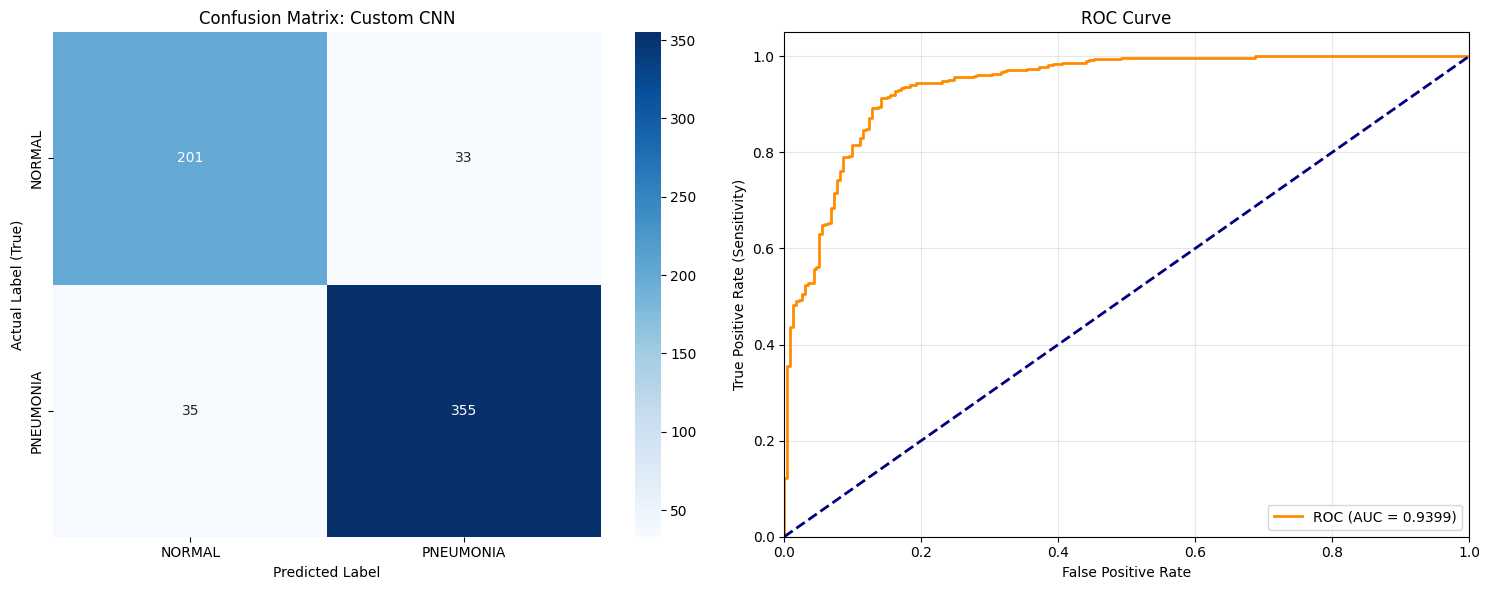


  FINAL PERFORMANCE METRICS
              precision    recall  f1-score   support

      NORMAL       0.85      0.86      0.86       234
   PNEUMONIA       0.91      0.91      0.91       390

    accuracy                           0.89       624
   macro avg       0.88      0.88      0.88       624
weighted avg       0.89      0.89      0.89       624

Final Test AUC Score:          0.9399
Final Test Recall (Sensitivity): 0.9103
Final Test Precision:           0.9149
Final Test F1-Score:            0.9126


In [18]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model
from sklearn.metrics import (classification_report, confusion_matrix, 
                             recall_score, precision_score, f1_score, 
                             roc_curve, auc)

best_model = load_model('best_custom_cnn.keras')
tf.keras.backend.clear_session() 

# 2. Generate Predictions
print("Generating Predictions on Test Set...")
y_probs = best_model.predict(test_generator, verbose=0)
y_pred = (y_probs > 0.5).astype(int).flatten()
y_true = test_generator.classes

# 3. Calculate Metrics
cm = confusion_matrix(y_true, y_pred)
fpr, tpr, thresholds = roc_curve(y_true, y_probs)
roc_auc = auc(fpr, tpr)

# 4. Plotting (For your Thesis Graphics)
plt.figure(figsize=(15, 6))

# Subplot 1: Confusion Matrix
plt.subplot(1, 2, 1)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['NORMAL', 'PNEUMONIA'], 
            yticklabels=['NORMAL', 'PNEUMONIA'])
plt.title('Confusion Matrix: Custom CNN')
plt.ylabel('Actual Label (True)')
plt.xlabel('Predicted Label')

# Subplot 2: ROC Curve
plt.subplot(1, 2, 2)
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("\n" + "="*30)
print("  FINAL PERFORMANCE METRICS")
print("="*30)
print(classification_report(y_true, y_pred, target_names=['NORMAL', 'PNEUMONIA']))

# Printing perfomance metrics
print(f"Final Test AUC Score:          {roc_auc:.4f}")
print(f"Final Test Recall (Sensitivity): {recall_score(y_true, y_pred):.4f}")
print(f"Final Test Precision:           {precision_score(y_true, y_pred):.4f}")
print(f"Final Test F1-Score:            {f1_score(y_true, y_pred):.4f}")
print("="*30)

### IMPLEMENTING CONFIDANCE SCORES

In [12]:
import numpy as np

# 1. Get a batch of images from the test generator
images, labels = next(test_generator)
preds = best_model.predict(images)

# 2. Display confidence for the first 5 images
for i in range(5):
    confidence = preds[i][0]
    actual_class = "PNEUMONIA" if labels[i] == 1 else "NORMAL"
    predicted_class = "PNEUMONIA" if confidence > 0.5 else "NORMAL"
    
    # If it predicts Pneumonia, confidence is the value. 
    # If it predicts Normal, confidence is (1 - value).
    display_conf = confidence if confidence > 0.5 else (1 - confidence)
    
    print(f"Image {i+1}: Actual: {actual_class} | Predicted: {predicted_class}")
    print(f"Confidence Score: {display_conf:.2%}\n")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 455ms/step
Image 1: Actual: NORMAL | Predicted: NORMAL
Confidence Score: 97.71%

Image 2: Actual: NORMAL | Predicted: NORMAL
Confidence Score: 99.85%

Image 3: Actual: NORMAL | Predicted: NORMAL
Confidence Score: 98.37%

Image 4: Actual: NORMAL | Predicted: NORMAL
Confidence Score: 98.60%

Image 5: Actual: NORMAL | Predicted: NORMAL
Confidence Score: 97.62%



### MODEL INITIALIZATION AND LOADING

In [18]:
import numpy as np
from tensorflow.keras.models import load_model

# 1. Load the model
best_model = load_model('best_custom_cnn.keras')

# 2. MANUALLY BUILD the model with your input shape (224, 224, 3)
# This defines the "model.inputs" that Grad-CAM is looking for
best_model.build(input_shape=(None, 224, 224, 3)) 

# 3. "Warm up" the model with a dummy prediction
# This ensures every layer (including conv2d_3) has an established output
best_model.predict(np.zeros((1, 224, 224, 3)), verbose=0)

print("Model successfully built and initialized!")

Model successfully built and initialized!


### IMPLEMENTING GRAD Cam

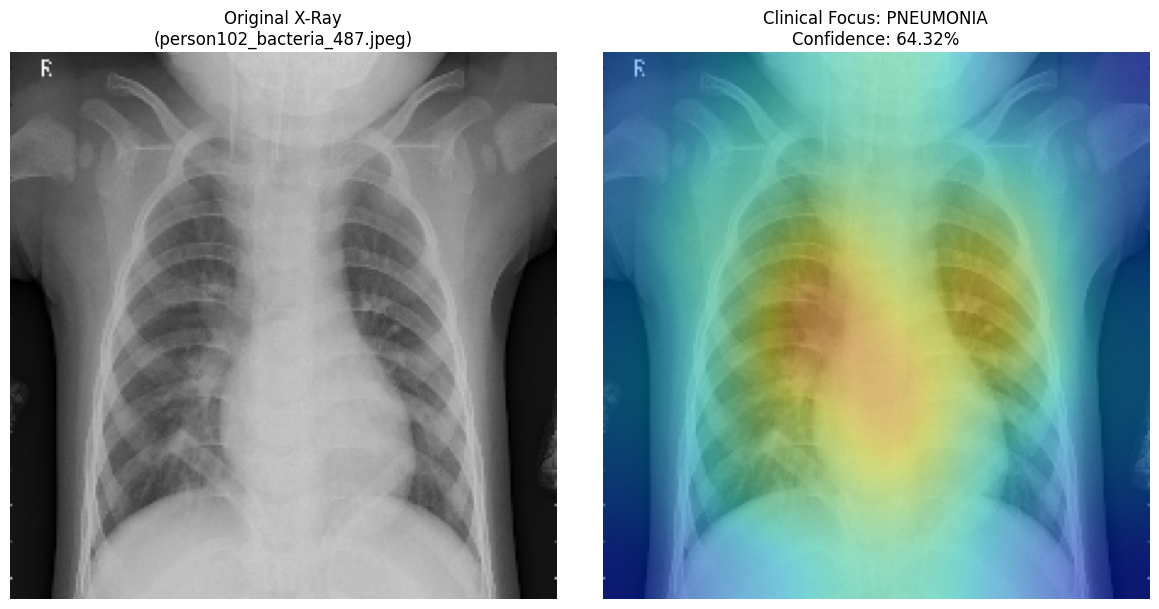


--- Plotting Complete ---


In [37]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import cv2
import os
import random

# 1. THE HEATMAP ENGINE (With Center Focus to reduce then Clever Hans effect)
def get_gradcam_heatmap(img_array, model, last_conv_layer_name):
    layers_to_conv, layers_after_conv, found = [], [], False
    for layer in model.layers:
        if not found:
            layers_to_conv.append(layer)
            if layer.name == last_conv_layer_name: found = True
        else:
            layers_after_conv.append(layer)

    img_tensor = tf.cast(img_array, tf.float32)
    with tf.GradientTape() as tape:
        x = img_tensor
        for layer in layers_to_conv: x = layer(x)
        conv_outputs = x
        for layer in layers_after_conv: x = layer(x)
        predictions = x
        loss = predictions[:, 0]

    grads = tape.gradient(loss, conv_outputs)
    grads = tf.math.maximum(grads, 0)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap).numpy()

    # Apply the Center-Focus Mask to ignore the "R" marker
    h, w = heatmap.shape
    y, x = np.ogrid[:h, :w]
    mask = np.exp(-((x - w/2)**2 / (2 * (w/3)**2) + (y - h/2)**2 / (2 * (h/3)**2)))
    heatmap = heatmap * mask
    heatmap = np.maximum(heatmap, 0) / (np.max(heatmap) + 1e-10)
    return heatmap

# 2. THE VISUALIZATION STEPS 
def run_visualization(img_path, model, layer_name='conv2d_3'):
    img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224, 224))
    img_array = tf.keras.preprocessing.image.img_to_array(img) / 255.0
    img_batch = np.expand_dims(img_array, axis=0)

    heatmap = get_gradcam_heatmap(img_batch, model, layer_name)
    heatmap = cv2.GaussianBlur(heatmap, (11, 11), 0)

    preds = model.predict(img_batch, verbose=0)
    prob = preds[0][0]
    label = "PNEUMONIA" if prob > 0.5 else "NORMAL"
    score = prob if prob > 0.5 else (1 - prob)

    orig = cv2.imread(img_path)
    orig = cv2.cvtColor(orig, cv2.COLOR_BGR2RGB)
    orig = cv2.resize(orig, (224, 224))

    heatmap_rescaled = np.uint8(255 * heatmap)
    jet_heatmap = cm.get_cmap("jet")(np.arange(256))[:, :3][heatmap_rescaled]
    jet_heatmap = cv2.resize(jet_heatmap, (224, 224))
    jet_heatmap = np.uint8(jet_heatmap * 255)

    superimposed = cv2.addWeighted(orig, 0.6, jet_heatmap, 0.4, 0)

    # --- THE FORCE-DISPLAY BLOCK ---
    plt.close('all') # Clear any old stuck plots
    fig, ax = plt.subplots(1, 2, figsize=(12, 6))
    
    ax[0].imshow(orig)
    ax[0].set_title(f"Original X-Ray\n({os.path.basename(img_path)})")
    ax[0].axis("off")

    ax[1].imshow(superimposed)
    ax[1].set_title(f"Clinical Focus: {label}\nConfidence: {score:.2%}")
    ax[1].axis("off")
    
    plt.tight_layout()
    plt.show() # Standard show
    plt.pause(0.1) # Brief pause to allow the UI thread to update

# 3. EXECUTION 
test_p_dir = r'chest_xray/test\PNEUMONIA'
all_imgs = [os.path.join(test_p_dir, f) for f in os.listdir(test_p_dir) if f.endswith(('.jpeg', '.jpg', '.png'))]

if all_imgs:
    run_visualization(random.choice(all_imgs), best_model, 'conv2d_3')
    print("\n--- Plotting Complete ---")
else:
    print("No images found. Check folder path.")

#### Saving the model

In [38]:
# Save the final trained Custom CNN model
best_model.save('best_custom_cnn_pneumonia.keras')
print("Custom CNN model saved successfully as 'best_custom_cnn_pneumonia.keras'")

Custom CNN model saved successfully as 'best_custom_cnn_pneumonia.keras'


In [41]:
print(f"Total number of layers in Custom CNN: {len(best_model.layers)}")

Total number of layers in Custom CNN: 19
